# Experiment No. 13: Explore DSS Software for Decision Analysis

**Aim:** To explore and apply a Decision Support System (DSS) tool to import, transform, visualize, and analyze decision-related data and generate actionable insights for managerial decision-making.

**Software:** This notebook demonstrates the data preparation and analysis in Python. The original experiment specifies Power BI, Tableau, or RapidMiner for building the interactive dashboard.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Create a sample business dataset

In [2]:
data = {
    'Order_ID': range(1, 16),
    'Region': ['North', 'South', 'East', 'West', 'North', 'South', 'East', 'West', 'North', 'South', 'East', 'West', 'North', 'South', 'East'],
    'Product': ['Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Tablet'],
    'Customer_Segment': ['Consumer', 'Corporate', 'Home Office', 'Consumer', 'Corporate', 'Home Office', 'Consumer', 'Corporate', 'Home Office', 'Consumer', 'Corporate', 'Home Office', 'Consumer', 'Corporate', 'Home Office'],
    'Sales': [1200, 850, 500, 1500, 900, 650, 1300, 950, 550, 1600, 1000, 700, 1400, 920, 600],
    'Profit': [180, 100, 60, 220, 80, 50, 170, 120, 40, 200, 90, 35, 190, 110, 55],
    'Discount': [0.05, 0.10, 0.00, 0.05, 0.20, 0.10, 0.10, 0.05, 0.15, 0.20, 0.10, 0.25, 0.05, 0.10, 0.15]
}
df = pd.DataFrame(data)
print("Business Sales Dataset:")
display(df.head(10))
print("\nDataset shape:", df.shape)

Business Sales Dataset:


,Order_ID,Region,Product,Customer_Segment,Sales,Profit,Discount
0,1,North,Laptop,Consumer,1200,180,0.05
1,2,South,Phone,Corporate,850,100,0.10
2,3,East,Tablet,Home Office,500,60,0.00
3,4,West,Laptop,Consumer,1500,220,0.05
4,5,North,Phone,Corporate,900,80,0.20
5,6,South,Tablet,Home Office,650,50,0.10
6,7,East,Laptop,Consumer,1300,170,0.10
7,8,West,Phone,Corporate,950,120,0.05
8,9,North,Tablet,Home Office,550,40,0.15
9,10,South,Laptop,Consumer,1600,200,0.20



Dataset shape: (15, 7)


## 3. Inspect and clean the dataset

In [3]:
print("Missing values:")
display(df.isnull().sum().to_frame('Missing Values'))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
# Convert columns to numeric types where needed
df['Sales'] = pd.to_numeric(df['Sales'], errors='coerce')
df['Profit'] = pd.to_numeric(df['Profit'], errors='coerce')
df['Discount'] = pd.to_numeric(df['Discount'], errors='coerce')
df = df.drop_duplicates()
df = df.dropna(subset=['Region', 'Product', 'Customer_Segment', 'Sales', 'Profit', 'Discount'])
print("\nRows after basic cleaning:", len(df))

Missing values:


,Missing Values
Order_ID,0
Region,0
Product,0
Customer_Segment,0
Sales,0
Profit,0
Discount,0



Duplicate rows: 0

Data types:
Order_ID              int64
Region               object
Product              object
Customer_Segment     object
Sales                 int64
Profit                int64
Discount            float64
dtype: object

Rows after basic cleaning: 15


## 4. Calculate decision-support measures

In [4]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
profit_margin = (total_profit / total_sales * 100) if total_sales else 0
average_discount = df['Discount'].mean() * 100
print(f"Total Sales: {total_sales:.2f}")
print(f"Total Profit: {total_profit:.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Discount: {average_discount:.2f}%")

Total Sales: 14620.00
Total Profit: 1700.00
Profit Margin: 11.63%
Average Discount: 11.00%


## 5. Regional performance analysis

,Region,Total_Sales,Total_Profit,Orders,Profit_Margin_%
1,North,4050,490,4,12.098765
2,South,4020,460,4,11.442786
0,East,3400,375,4,11.029412
3,West,3150,375,3,11.904762


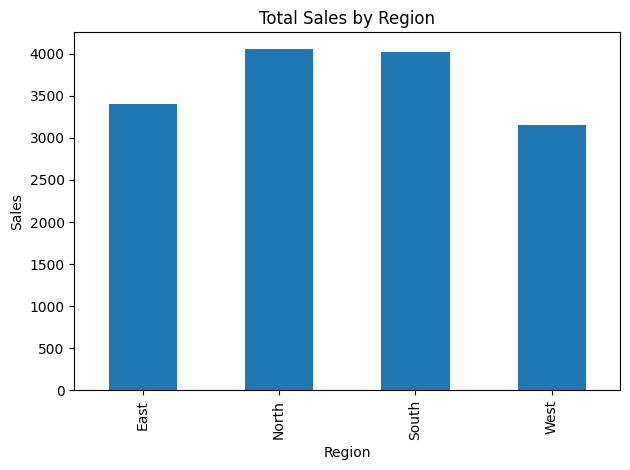

In [5]:
region_summary = df.groupby('Region', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'), Orders=('Order_ID', 'count')
)
region_summary['Profit_Margin_%'] = region_summary['Total_Profit'] / region_summary['Total_Sales'] * 100
display(region_summary.sort_values('Total_Sales', ascending=False))
region_summary.plot(x='Region', y='Total_Sales', kind='bar', legend=False)
plt.title('Total Sales by Region')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

## 6. Product performance analysis

,Product,Total_Sales,Total_Profit,Orders,Profit_Margin_%
0,Laptop,7000,960,5,13.714286
1,Phone,4620,500,5,10.822511
2,Tablet,3000,240,5,8.000000


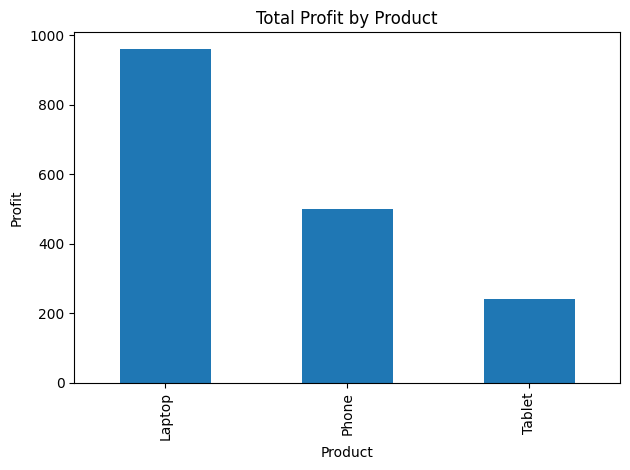

In [6]:
product_summary = df.groupby('Product', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'), Orders=('Order_ID', 'count')
)
product_summary['Profit_Margin_%'] = product_summary['Total_Profit'] / product_summary['Total_Sales'] * 100
display(product_summary.sort_values('Total_Profit', ascending=False))
product_summary.plot(x='Product', y='Total_Profit', kind='bar', legend=False)
plt.title('Total Profit by Product')
plt.ylabel('Profit')
plt.tight_layout()
plt.show()

## 7. Customer segment analysis

,Customer_Segment,Total_Sales,Total_Profit,Orders,Profit_Margin_%
0,Consumer,7000,960,5,13.714286
1,Corporate,4620,500,5,10.822511
2,Home Office,3000,240,5,8.000000


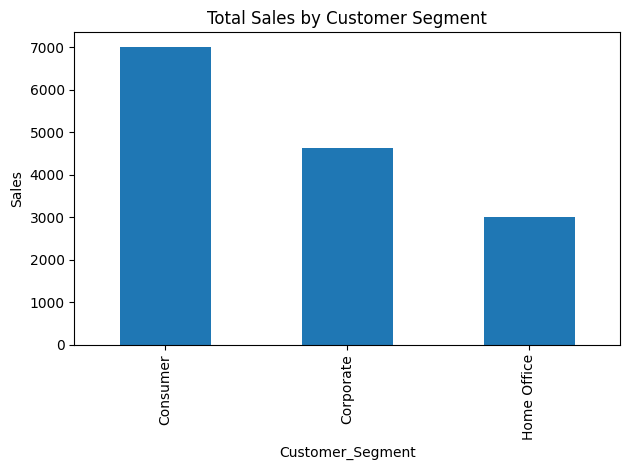

In [7]:
segment_summary = df.groupby('Customer_Segment', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'), Orders=('Order_ID', 'count')
)
segment_summary['Profit_Margin_%'] = segment_summary['Total_Profit'] / segment_summary['Total_Sales'] * 100
display(segment_summary.sort_values('Total_Sales', ascending=False))
segment_summary.plot(x='Customer_Segment', y='Total_Sales', kind='bar', legend=False)
plt.title('Total Sales by Customer Segment')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

## 8. Analyze discount and profitability

,Discount,Average_Sales,Average_Profit
0,0.00,500.0,60.0
1,0.05,1262.5,177.5
2,0.10,944.0,104.0
3,0.15,575.0,47.5
4,0.20,1250.0,140.0
5,0.25,700.0,35.0


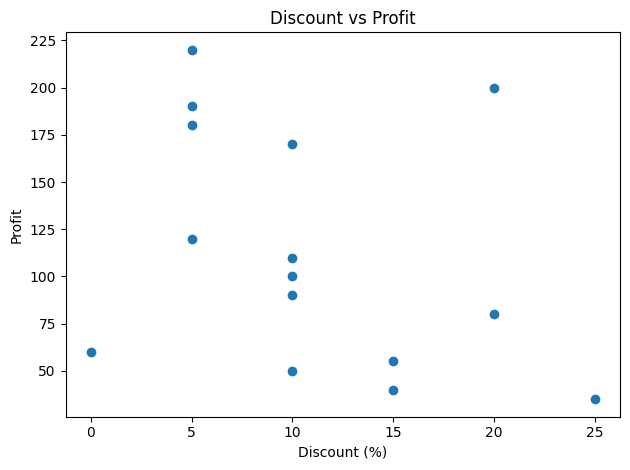

Correlation between discount and profit: -0.337


In [8]:
discount_summary = df.groupby('Discount', as_index=False).agg(
    Average_Sales=('Sales', 'mean'), Average_Profit=('Profit', 'mean')
)
display(discount_summary)
plt.scatter(df['Discount'] * 100, df['Profit'])
plt.title('Discount vs Profit')
plt.xlabel('Discount (%)')
plt.ylabel('Profit')
plt.tight_layout()
plt.show()
print("Correlation between discount and profit:", round(df["Discount"].corr(df["Profit"]), 3))

## 9. Generate decision-support observations

In [9]:
best_region = region_summary.loc[region_summary['Total_Sales'].idxmax()]
best_product = product_summary.loc[product_summary['Total_Profit'].idxmax()]
best_segment = segment_summary.loc[segment_summary['Total_Profit'].idxmax()]
print(f"Highest-sales region: {best_region['Region']} (sales = {best_region['Total_Sales']:.2f})")
print(f"Highest-profit product: {best_product['Product']} (profit = {best_product['Total_Profit']:.2f})")
print(f"Highest-profit customer segment: {best_segment['Customer_Segment']} (profit = {best_segment['Total_Profit']:.2f})")
if df['Discount'].corr(df['Profit']) < 0:
    print('Observation: Discount and profit have a negative correlation in this sample; review high-discount offers.')
elif df['Discount'].corr(df['Profit']) > 0:
    print('Observation: Discount and profit have a positive correlation in this sample; examine product and order mix before changing discount policy.')
else:
    print('Observation: No linear correlation between discount and profit is observed in this sample.')
print("\nRecommendation: Use the regional, product, and segment summaries to identify strong performers and areas requiring further investigation. These results are based on illustrative sample data.")

Highest-sales region: North (sales = 4050.00)
Highest-profit product: Laptop (profit = 960.00)
Highest-profit customer segment: Consumer (profit = 960.00)
Observation: Discount and profit have a negative correlation in this sample; review high-discount offers.

Recommendation: Use the regional, product, and segment summaries to identify strong performers and areas requiring further investigation. These results are based on illustrative sample data.


## Result
A basic business decision-analysis workflow was implemented in Python. The dataset was inspected and cleaned, measures such as total sales, total profit, profit margin, and average discount were calculated, and regional, product, customer-segment, and discount-profit analyses were performed. The summaries can inform an interactive dashboard in Power BI, Tableau, or RapidMiner.